# LUMA - Lokalny Urok Mistrzostwa Artystycznego

LUMA to lokalny jarmark, który rośnie z tygodnia na tydzień; coraz więcej wystawców, więc coraz więcej gości (miejscowych i turystów), okazjonalne promocje i sezonowość

## Import Bibliotek

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Wygenerowanue syntetycznych danych

### Ustawienie ziarna RNG

In [21]:
RNG_SEED = 20261020
rng = np.random.default_rng(RNG_SEED)
print('Ustawiono ziarno RNG: ', RNG_SEED)

Ustawiono ziarno RNG:  20261020


### Zdefiniowanie "stałych"

In [43]:
LUMA_FULL = "Lokalny Urok Mistrzostwa Artystycznego"
CATEGORIES = ["Ceramika", "Tekstylia", "Biżuteria", "Rękodzieło", "Przetwory", "Dekoracje", "Stolarka", "Masarstwo", "Alkohole"]

### Przygotowanie bazowych danych syntetycznych

Katalog kategorii i ich bazowe parametry generatywne (statyczne)

In [44]:
catalog = pd.DataFrame({
    "category": CATEGORIES,
    "demand_loc_base": [120, 180, 130, 80, 160, 150, 70, 90, 110], # średni popyt lokalny (szt./tydz.)
    "demand_tur_base": [60, 40, 80, 30, 90, 30, 50, 40, 80], # średni popyt turystyczny (szt./tydz.)
    "price_pln_base": [8, 120, 150, 230, 40, 35, 250, 215, 135], # średnia cena jednostkowa (PLN/szt.)
})

Wyliczony 'typowy' przychód tygodniowy: (lokalny + turyści) * cena

In [46]:
catalog["revenue_avg_pln"] = (catalog["demand_loc_base"] + catalog["demand_tur_base"]) * catalog["price_pln_base"]

In [47]:
catalog

,category,demand_loc_base,demand_tur_base,price_pln_base,revenue_avg_pln
0,Ceramika,120,60,8,1440
1,Tekstylia,180,40,120,26400
2,Biżuteria,130,80,150,31500
3,Rękodzieło,80,30,230,25300
4,Przetwory,160,90,40,10000
5,Dekoracje,150,30,35,6300
6,Stolarka,70,50,250,30000
7,Masarstwo,90,40,215,27950
8,Alkohole,110,80,135,25650


### Przygotowanie funkcji pomocniczych do generowania danych tygodniowych

Generowanie popytu lokalnego i turystycznego na podstawie danych bazowych, z losowym szumem (multiplikatywnym) i opcjonalnymi boostami (%).

In [49]:
def determine_demand(catalog, rng, variance=0.15, boost_loc=0.0, boost_tur=0.0):
    df = catalog[["category", "demand_loc_base", "demand_tur_base"]].copy()
    eps_loc = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)
    eps_tur = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)
    df["demand_loc"] = (df["demand_loc_base"] * (1 + boost_loc)) * eps_loc
    df["demand_tur"] = (df["demand_tur_base"] * (1 + boost_tur)) * eps_tur 
    df["demand_loc"] = np.maximum(df["demand_loc"].round().astype(int), 0)
    df["demand_tur"] = np.maximum(df["demand_tur"].round().astype(int), 0)
    return df[["category", "demand_loc", "demand_tur"]]

Wyliczenie przychodu lokalnego, turystycznego i łącznego.

In [50]:
def count_revenue(catalog, demand_df):
    df = demand_df.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
    df["revenue_loc"] = df["demand_loc"] * df["price_pln_base"]
    df["revenue_tur"] = df["demand_tur"] * df["price_pln_base"]
    df["revenue_pln"] = df["revenue_loc"] + df["revenue_tur"]
    return df[["category", "revenue_loc", "revenue_tur", "revenue_pln"]]

Generowanie danych tygodniowych

In [51]:
def generate_weekly_data(catalog, rng, variance=0.15, boost_loc=0.0, boost_tur=0.0):
    demand_df = determine_demand(catalog, rng, variance=variance, boost_loc=boost_loc, boost_tur=boost_tur)
    revenue_df = count_revenue(catalog, demand_df)
    return revenue_df

### Wygenerowanie danych tygodniowych

In [57]:
t1 = generate_weekly_data(catalog, rng)
t1 = t1.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
print("Tydzień 1 - przychody per kategoria (PLN)")
display(t1)
print("Łączny przychód w tygodniu 1 (PLN): ", t1["revenue_pln"].sum())

Tydzień 1 - przychody per kategoria (PLN)


,category,revenue_loc,revenue_tur,revenue_pln,price_pln_base
0,Ceramika,1096,488,1584,8
1,Tekstylia,20640,7080,27720,120
2,Biżuteria,18750,16350,35100,150
3,Rękodzieło,19550,7360,26910,230
4,Przetwory,7600,4760,12360,40
5,Dekoracje,5040,805,5845,35
6,Stolarka,16250,8500,24750,250
7,Masarstwo,19350,9245,28595,215
8,Alkohole,15660,11610,27270,135


Łączny przychód w tygodniu 1 (PLN):  190134


## Analiza i wizualizacja danych

Podstawowe wykresy

<Axes: >

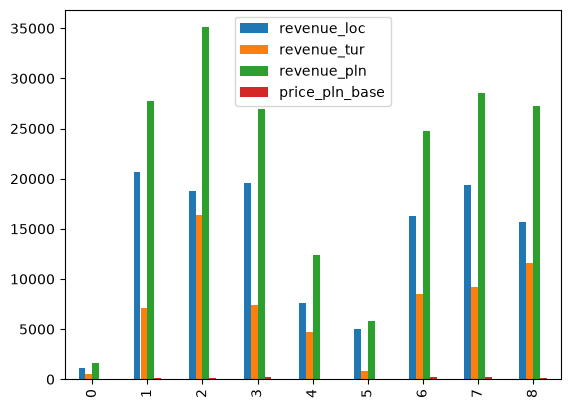

In [58]:
t1.plot.bar()

<Axes: >

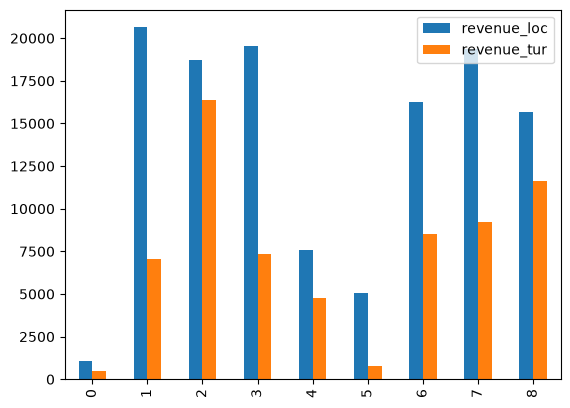

In [59]:
t1[["revenue_loc", "revenue_tur"]].plot.bar()

<Axes: >

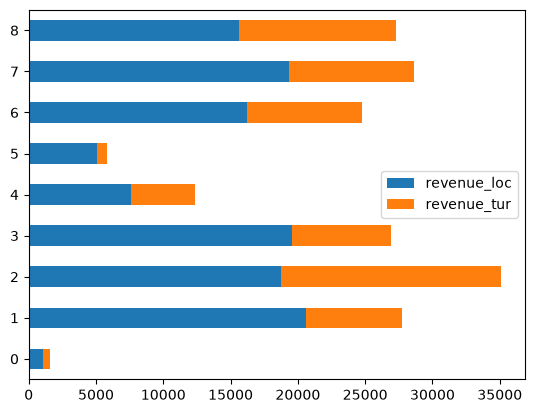

In [60]:
t1[["revenue_loc", "revenue_tur"]].plot.barh(stacked=True)

Minimalny wykres

<BarContainer object of 9 artists>

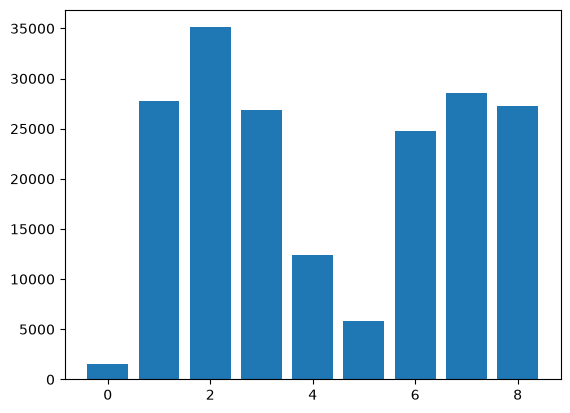

In [64]:
hoights = t1["revenue_pln"]
plt.bar(range(len(hoights)), hoights)

Jawne tworzenie i wyświetlanie wykresu

In [65]:
hoights = t1["revenue_pln"]
categories = t1["category"]

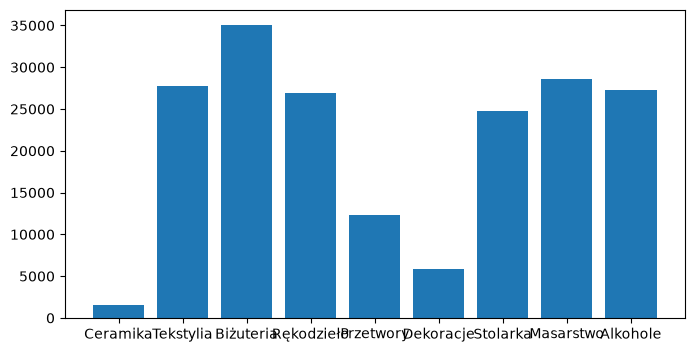

In [66]:
plt.figure(figsize=(8, 4))
plt.bar(categories, hoights)
plt.show()

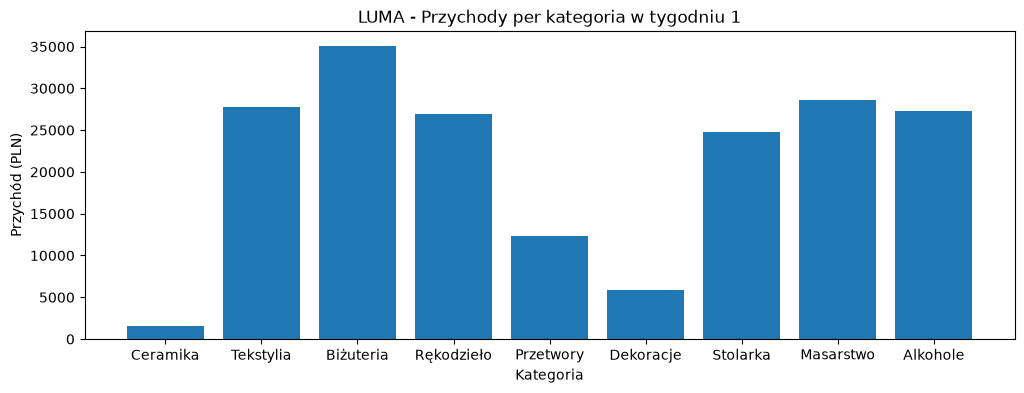

In [67]:
plt.figure(figsize=(12, 4))
plt.bar(categories, hoights)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.show()

Etykiety wartości i formatowanie liczb